# GAN-A Phase 1: Data Setup

This notebook:

1. Creates `train/` and `test/` folders (each with `image/`, `mask/`, `outline/`, and `binary_mask/` subfolders)

2. Splits paired data into 90% train / 10% test while keeping all four modalities filename-aligned

3. Augments training data (flips, rotations, crops) with identical transforms across all four paired inputs

4. Keeps images at 500x500 on disk; resizing happens at load time during training

In [4]:
# =============================================================
# CONFIGURATION — Change these paths to switch datasets easily
# =============================================================
import os
import shutil
import random
import numpy as np
from PIL import Image
from tqdm import tqdm

# ----- SOURCE DATA (paired files with matching filenames) -----
SOURCE_MASKED_DIR = r'C:/Users/henry/Desktop/isef2026/data/gan_a/phase_1/healthy_masked'
SOURCE_TARGET_DIR = r'C:/Users/henry/Desktop/isef2026/data/gan_a/phase_1/healthy_target'
SOURCE_OUTLINE_DIR = r'C:/Users/henry/Desktop/isef2026/data/gan_a/phase_1/healthy_outline'
SOURCE_BINARY_DIR = r'C:/Users/henry/Desktop/isef2026/data/gan_a/phase_1/lesion_synthetic_binary_processed' # enlarged morph opened + dilated version

# ----- OUTPUT ROOT (train/test splits will be created here) -----
OUTPUT_ROOT = r'C:/Users/henry/Desktop/isef2026/data/gan_a/phase_1/experiment'

# ----- SPLIT RATIO -----
TRAIN_RATIO = 0.9   # 90% train, 10% test

# ----- AUGMENTATION CONFIG -----
NUM_AUGMENTATIONS_PER_IMAGE = 3  # number of augmented copies per training image
RANDOM_SEED = 42

print('Configuration loaded.')
print(f'Using binary source dir: {SOURCE_BINARY_DIR}')

Configuration loaded.
Using binary source dir: C:/Users/henry/Desktop/isef2026/data/gan_a/phase_1/lesion_synthetic_binary_processed


In [6]:
# =============================================================
# 1. Create train/test folder structure
# =============================================================

TRAIN_OUTLINE_DIR = os.path.join(OUTPUT_ROOT, 'train', 'outline')
TEST_OUTLINE_DIR = os.path.join(OUTPUT_ROOT, 'test', 'outline')
TRAIN_BINARY_DIR = os.path.join(OUTPUT_ROOT, 'train', 'binary_mask')
TEST_BINARY_DIR = os.path.join(OUTPUT_ROOT, 'test', 'binary_mask')

dirs_to_create = [
    os.path.join(OUTPUT_ROOT, 'train', 'image'),
    os.path.join(OUTPUT_ROOT, 'train', 'mask'),
    TRAIN_OUTLINE_DIR,
    TRAIN_BINARY_DIR,
    os.path.join(OUTPUT_ROOT, 'test', 'image'),
    os.path.join(OUTPUT_ROOT, 'test', 'mask'),
    TEST_OUTLINE_DIR,
    TEST_BINARY_DIR,
]
for d in dirs_to_create:
    os.makedirs(d, exist_ok=True)
    print(f'Created: {d}')

Created: C:/Users/henry/Desktop/isef2026/data/gan_a/phase_1/experiment\train\image
Created: C:/Users/henry/Desktop/isef2026/data/gan_a/phase_1/experiment\train\mask
Created: C:/Users/henry/Desktop/isef2026/data/gan_a/phase_1/experiment\train\outline
Created: C:/Users/henry/Desktop/isef2026/data/gan_a/phase_1/experiment\train\binary_mask
Created: C:/Users/henry/Desktop/isef2026/data/gan_a/phase_1/experiment\test\image
Created: C:/Users/henry/Desktop/isef2026/data/gan_a/phase_1/experiment\test\mask
Created: C:/Users/henry/Desktop/isef2026/data/gan_a/phase_1/experiment\test\outline
Created: C:/Users/henry/Desktop/isef2026/data/gan_a/phase_1/experiment\test\binary_mask


In [5]:
# =============================================================
# 2. Gather paired filenames and split into train/test
# =============================================================
masked_files = sorted([f for f in os.listdir(SOURCE_MASKED_DIR) if f.lower().endswith('.png')])
target_files = sorted([f for f in os.listdir(SOURCE_TARGET_DIR) if f.lower().endswith('.png')])
outline_files = sorted([f for f in os.listdir(SOURCE_OUTLINE_DIR) if f.lower().endswith('.png')])
binary_files = sorted([f for f in os.listdir(SOURCE_BINARY_DIR) if f.lower().endswith('.png')])

assert len(masked_files) == len(target_files) == len(outline_files) == len(binary_files), (
    f'Mismatch counts: masked={len(masked_files)}, target={len(target_files)}, '
    f'outline={len(outline_files)}, binary={len(binary_files)}'
)
assert masked_files == target_files == outline_files == binary_files, (
    'Filenames do not match across masked/target/outline/binary folders!'
)

# Shuffle with fixed seed for reproducibility
random.seed(RANDOM_SEED)
indices = list(range(len(masked_files)))
random.shuffle(indices)

split_idx = int(len(indices) * TRAIN_RATIO)
train_indices = indices[:split_idx]
test_indices = indices[split_idx:]

print(f'Total paired samples: {len(masked_files)}')
print(f'Train: {len(train_indices)} | Test: {len(test_indices)}')

Total paired samples: 380
Train: 342 | Test: 38


In [7]:
# =============================================================
# 3. Copy test data (NO augmentation — keep originals clean)
# =============================================================
for idx in tqdm(test_indices, desc='Copying test set'):
    fname = masked_files[idx]
    # Input image (masked/synthetic diseased leaf)
    shutil.copy2(
        os.path.join(SOURCE_MASKED_DIR, fname),
        os.path.join(OUTPUT_ROOT, 'test', 'image', fname)
    )
    # Target image (healthy)
    shutil.copy2(
        os.path.join(SOURCE_TARGET_DIR, fname),
        os.path.join(OUTPUT_ROOT, 'test', 'mask', fname)
    )
    # Leaf outline
    shutil.copy2(
        os.path.join(SOURCE_OUTLINE_DIR, fname),
        os.path.join(TEST_OUTLINE_DIR, fname)
    )
    # Lesion binary mask
    shutil.copy2(
        os.path.join(SOURCE_BINARY_DIR, fname),
        os.path.join(TEST_BINARY_DIR, fname)
    )

print(f'Copied {len(test_indices)} test quadruplets.')

Copying test set: 100%|██████████| 38/38 [00:00<00:00, 323.52it/s]

Copied 38 test quadruplets.


In [8]:
# =============================================================
# 4. Copy originals + augment training data
#    Augmentations: random flips, rotations, crops
#    image, mask, outline, and binary_mask get THE SAME transform
# =============================================================

def augment_quad(img, mask, outline, binary_mask, seed):
    """Apply identical random augmentation to all four paired modalities."""
    rng = random.Random(seed)

    # Random horizontal flip
    if rng.random() > 0.5:
        img = img.transpose(Image.FLIP_LEFT_RIGHT)
        mask = mask.transpose(Image.FLIP_LEFT_RIGHT)
        outline = outline.transpose(Image.FLIP_LEFT_RIGHT)
        binary_mask = binary_mask.transpose(Image.FLIP_LEFT_RIGHT)

    # Random vertical flip
    if rng.random() > 0.5:
        img = img.transpose(Image.FLIP_TOP_BOTTOM)
        mask = mask.transpose(Image.FLIP_TOP_BOTTOM)
        outline = outline.transpose(Image.FLIP_TOP_BOTTOM)
        binary_mask = binary_mask.transpose(Image.FLIP_TOP_BOTTOM)

    # Random rotation (0, 90, 180, or 270 degrees)
    angle = rng.choice([0, 90, 180, 270])
    if angle != 0:
        img = img.rotate(angle, expand=False)
        mask = mask.rotate(angle, expand=False)
        outline = outline.rotate(angle, expand=False)
        binary_mask = binary_mask.rotate(angle, expand=False)

    # Random crop (80-100%) then resize back to original size
    w, h = img.size
    crop_scale = rng.uniform(0.8, 1.0)
    crop_w = int(w * crop_scale)
    crop_h = int(h * crop_scale)
    left = rng.randint(0, w - crop_w)
    top = rng.randint(0, h - crop_h)

    img = img.crop((left, top, left + crop_w, top + crop_h)).resize((w, h), Image.BILINEAR)
    mask = mask.crop((left, top, left + crop_w, top + crop_h)).resize((w, h), Image.BILINEAR)
    outline = outline.crop((left, top, left + crop_w, top + crop_h)).resize((w, h), Image.NEAREST)
    binary_mask = binary_mask.crop((left, top, left + crop_w, top + crop_h)).resize((w, h), Image.NEAREST)

    return img, mask, outline, binary_mask

count = 0
for idx in tqdm(train_indices, desc='Augmenting train set'):
    fname = masked_files[idx]
    base = os.path.splitext(fname)[0]

    img = Image.open(os.path.join(SOURCE_MASKED_DIR, fname)).convert('RGB')
    mask = Image.open(os.path.join(SOURCE_TARGET_DIR, fname)).convert('RGB')
    outline = Image.open(os.path.join(SOURCE_OUTLINE_DIR, fname)).convert('L')
    binary_mask = Image.open(os.path.join(SOURCE_BINARY_DIR, fname)).convert('L')

    # Save original
    img.save(os.path.join(OUTPUT_ROOT, 'train', 'image', f'{base}_orig.png'))
    mask.save(os.path.join(OUTPUT_ROOT, 'train', 'mask', f'{base}_orig.png'))
    outline.save(os.path.join(TRAIN_OUTLINE_DIR, f'{base}_orig.png'))
    binary_mask.save(os.path.join(TRAIN_BINARY_DIR, f'{base}_orig.png'))
    count += 1

    # Save augmented copies
    for aug_i in range(NUM_AUGMENTATIONS_PER_IMAGE):
        seed = RANDOM_SEED + idx * 100 + aug_i
        aug_img, aug_mask, aug_outline, aug_binary = augment_quad(
            img.copy(), mask.copy(), outline.copy(), binary_mask.copy(), seed
        )
        aug_img.save(os.path.join(OUTPUT_ROOT, 'train', 'image', f'{base}_aug{aug_i}.png'))
        aug_mask.save(os.path.join(OUTPUT_ROOT, 'train', 'mask', f'{base}_aug{aug_i}.png'))
        aug_outline.save(os.path.join(TRAIN_OUTLINE_DIR, f'{base}_aug{aug_i}.png'))
        aug_binary.save(os.path.join(TRAIN_BINARY_DIR, f'{base}_aug{aug_i}.png'))
        count += 1

print(f'Saved {count} training quadruplets (originals + augmentations).')

Augmenting train set: 100%|██████████| 342/342 [03:09<00:00,  1.81it/s]

Saved 1368 training quadruplets (originals + augmentations).


Train image: 1368 | mask: 1368 | outline: 1368 | binary: 1368
Test  image: 38 | mask: 38 | outline: 38 | binary: 38
All filenames match across image/mask/outline/binary_mask folders.


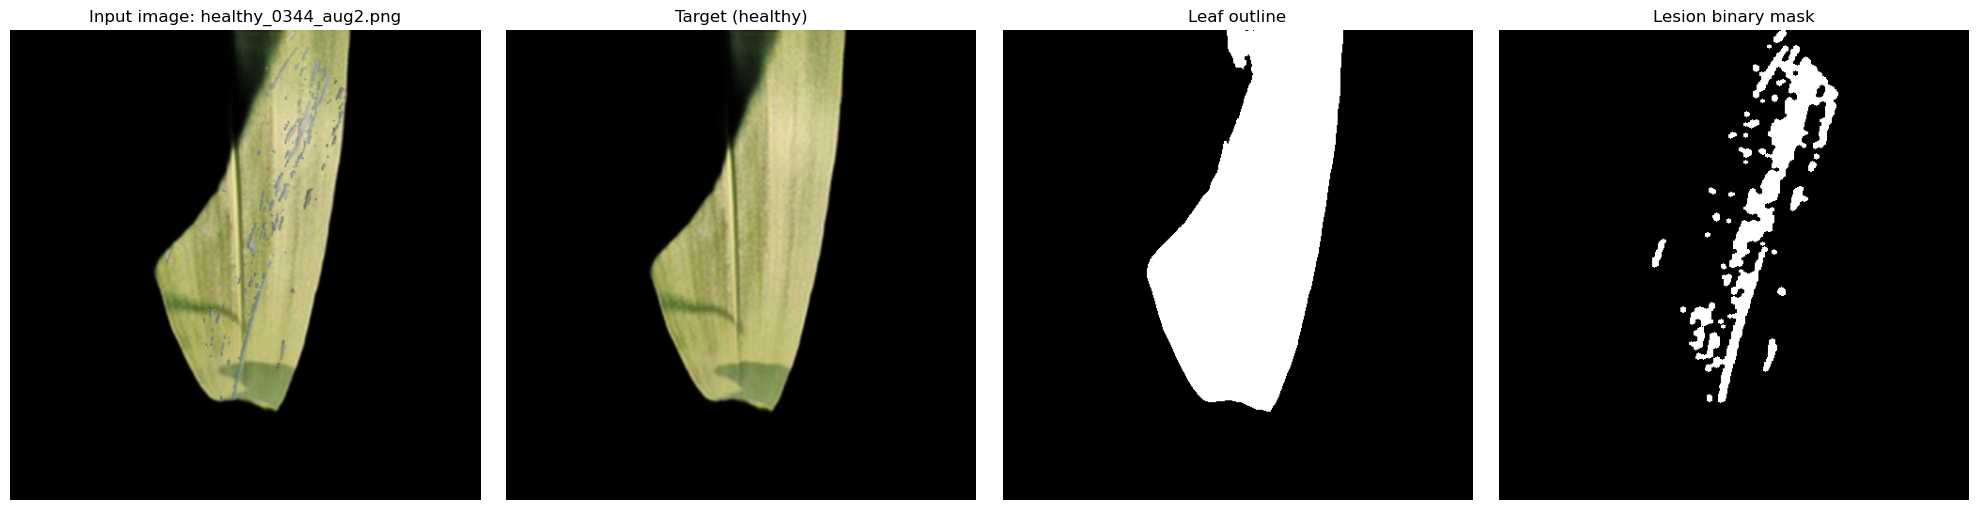

: 

In [ ]:
# =============================================================
# 5. Verify: print counts and show a random matched quadruplet
# =============================================================
import matplotlib.pyplot as plt

train_imgs = sorted(os.listdir(os.path.join(OUTPUT_ROOT, 'train', 'image')))
train_masks = sorted(os.listdir(os.path.join(OUTPUT_ROOT, 'train', 'mask')))
train_outlines = sorted(os.listdir(os.path.join(OUTPUT_ROOT, 'train', 'outline')))
train_binary = sorted(os.listdir(os.path.join(OUTPUT_ROOT, 'train', 'binary_mask')))

test_imgs = sorted(os.listdir(os.path.join(OUTPUT_ROOT, 'test', 'image')))
test_masks = sorted(os.listdir(os.path.join(OUTPUT_ROOT, 'test', 'mask')))
test_outlines = sorted(os.listdir(os.path.join(OUTPUT_ROOT, 'test', 'outline')))
test_binary = sorted(os.listdir(os.path.join(OUTPUT_ROOT, 'test', 'binary_mask')))

print(f'Train image: {len(train_imgs)} | mask: {len(train_masks)} | outline: {len(train_outlines)} | binary: {len(train_binary)}')
print(f'Test  image: {len(test_imgs)} | mask: {len(test_masks)} | outline: {len(test_outlines)} | binary: {len(test_binary)}')

assert train_imgs == train_masks == train_outlines == train_binary, 'MISMATCH in training filenames!'
assert test_imgs == test_masks == test_outlines == test_binary, 'MISMATCH in test filenames!'
print('All filenames match across image/mask/outline/binary_mask folders.')

# Show a random training quadruplet
sample = random.choice(train_imgs)
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
axs[0].imshow(Image.open(os.path.join(OUTPUT_ROOT, 'train', 'image', sample)))
axs[0].set_title(f'Input image: {sample}')
axs[0].axis('off')

axs[1].imshow(Image.open(os.path.join(OUTPUT_ROOT, 'train', 'mask', sample)))
axs[1].set_title('Target (healthy)')
axs[1].axis('off')

axs[2].imshow(Image.open(os.path.join(OUTPUT_ROOT, 'train', 'outline', sample)), cmap='gray')
axs[2].set_title('Leaf outline')
axs[2].axis('off')

axs[3].imshow(Image.open(os.path.join(OUTPUT_ROOT, 'train', 'binary_mask', sample)), cmap='gray', vmin=0, vmax=255)
axs[3].set_title('Lesion binary mask')
axs[3].axis('off')

plt.tight_layout()
plt.show()